## Vessel Passage Patterns around Anholt (Flag 13)

### Dataset Overview
A constructed Danish AIS-style case with 60 complete trajectories on three recurrent passages around Anholt in Kattegat. Static vessel dimensions and separate route/island reference tables support route-use comparisons without exposing route labels in the trajectory table.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze vessel movement patterns around the island and investigate differences in route use.

Role: Maritime traffic analyst


Category: Anholt island passage geometry and vessel-characteristic differences

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What are the main vessel-movement routes around the island?

#### Analysis action

Compare complete trajectory geometry with the three supplied passage references.

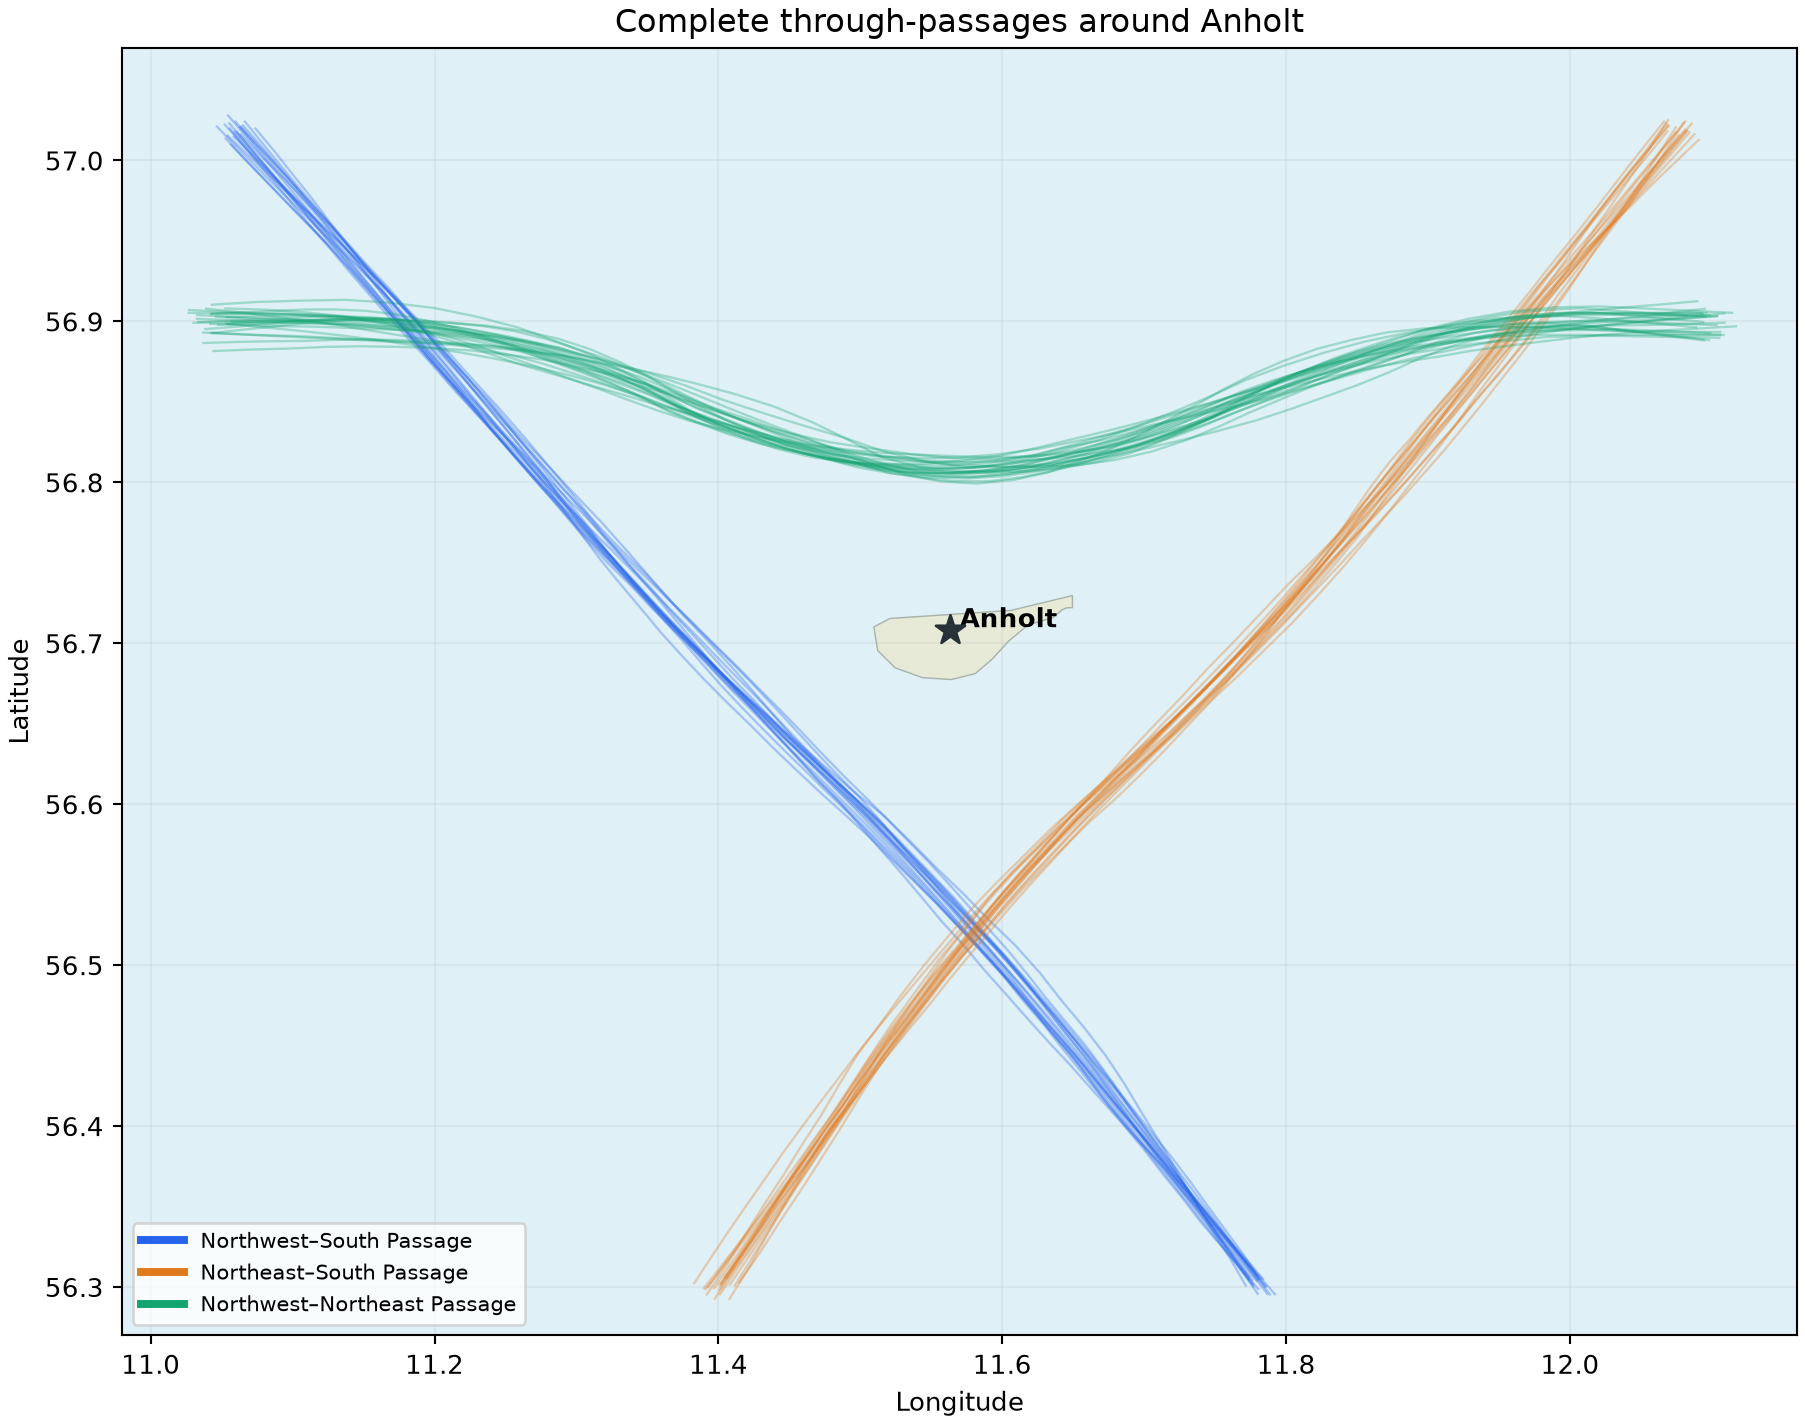

In [ ]:
import pandas as pd
from pathlib import Path
points=pd.read_csv(dataset_path); refs=pd.read_csv(Path('route_references.csv')); island=pd.read_csv(Path('island_reference.csv'))
print(refs.groupby('route_name').size()); print(island)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/island_three_passages.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "island_passage_structure",
  "insight": "Vessel traffic around the island is organized into three main passage routes.",
  "insight_value": {
    "route_counts": {
      "NW_S": 18,
      "NE_S": 18,
      "NW_NE": 24
    }
  },
  "plot": {
    "plot_type": "geographic_route_map",
    "title": "Three Complete Passages around Anholt",
    "file": "visualizations/island_three_passages.png",
    "description": "Complete through-trajectories extend beyond the three sides of the passage structure surrounding Anholt."
  },
  "question": "What are the main vessel-movement routes around the island?",
  "actionable_insight": "Compare complete trajectory geometry with the three supplied passage references.",
  "code": "import pandas as pd\nfrom pathlib import Path\npoints=pd.read_csv(dataset_path); refs=pd.read_csv(Path('route_references.csv')); island=pd.read_csv(Path('island_reference.csv'))\nprint(refs.groupby('route_name').size()); print(island)",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference",
    "vessel_id"
  ]
}

### **Question 2**: How do speed stability and heading/COG profiles differ among the three passages?

#### Analysis action

Orient trajectories to a common route direction, normalize trip progress, and compare Heading and COG deviations and their recovery toward the entry direction.

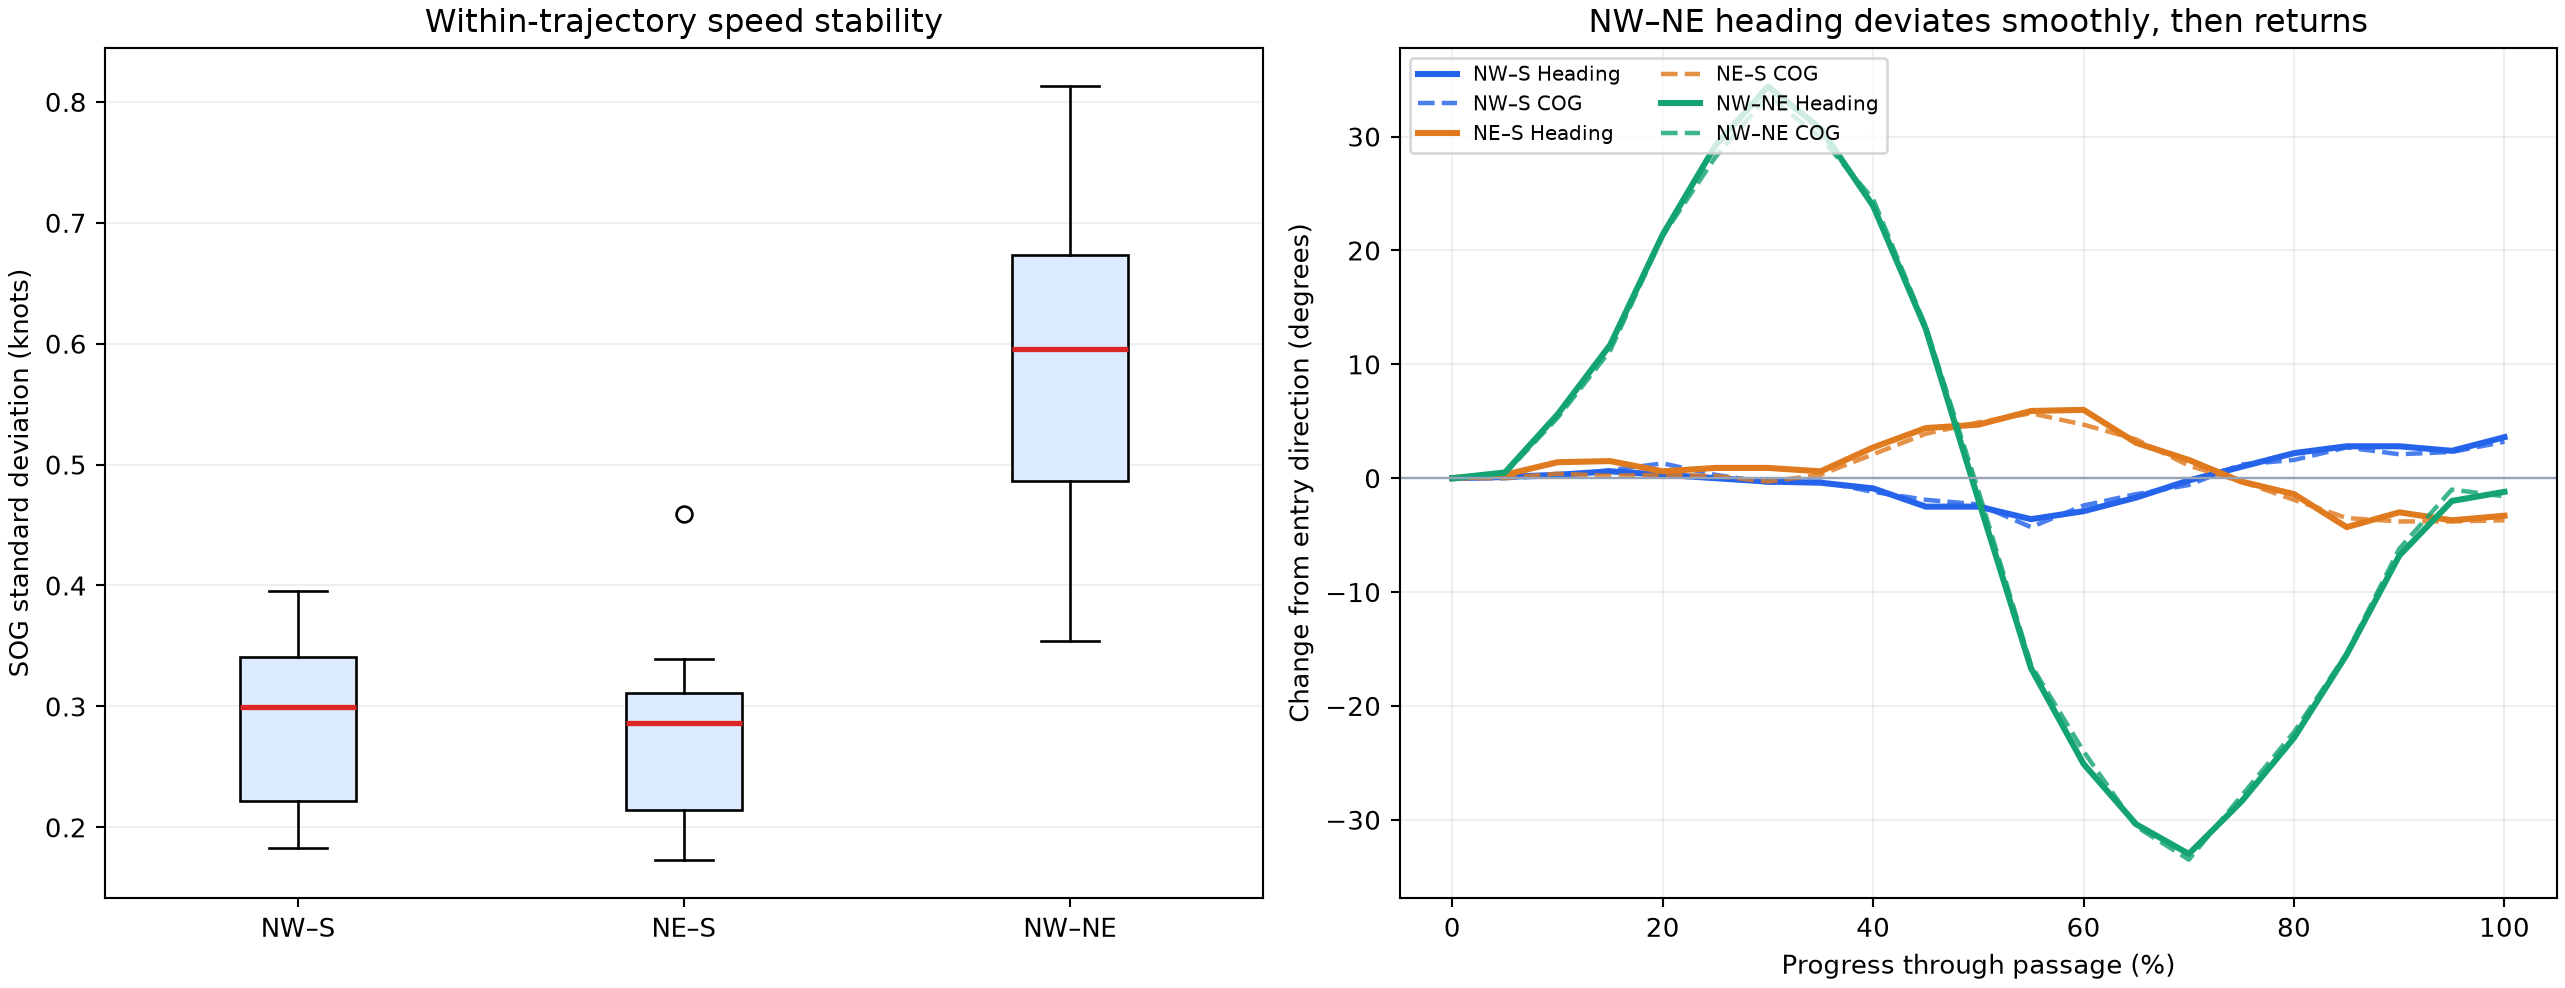

In [ ]:
import pandas as pd
points=pd.read_csv(dataset_path)
gap=((points.heading-points.cog+180)%360-180).abs()
print(points.groupby('trajectory_id').sog_knots.std().describe()); print(gap.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_and_direction_by_passage.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "passage_speed_and_course_pattern",
  "insight": "Two of the three main routes show a stable speed distribution and a consistent direction of travel, while the other shows a smooth change of direction.",
  "insight_value": {
    "median_peak_to_peak_heading_change_deg": {
      "NW_S": 11.2,
      "NE_S": 13.6,
      "NW_NE": 71.1
    },
    "median_exit_heading_difference_deg": {
      "NW_S": 2.8,
      "NE_S": 3.5,
      "NW_NE": 6.5
    },
    "median_absolute_heading_cog_gap_deg": {
      "NW_S": 0.9,
      "NE_S": 0.9,
      "NW_NE": 0.9
    },
    "median_speed_sd_knots": {
      "NW_S": 0.3,
      "NE_S": 0.29,
      "NW_NE": 0.6
    }
  },
  "plot": {
    "plot_type": "speed_boxplot_and_direction_profile",
    "title": "Speed Stability and Heading–COG Change by Passage",
    "file": "visualizations/speed_and_direction_by_passage.png",
    "description": "NW–S and NE–S retain nearly constant heading. NW–NE turns slightly southward, then northward and returns close to its entry direction, while COG follows Heading throughout."
  },
  "question": "How do speed stability and heading/COG profiles differ among the three passages?",
  "actionable_insight": "Orient trajectories to a common route direction, normalize trip progress, and compare Heading and COG deviations and their recovery toward the entry direction.",
  "code": "import pandas as pd\npoints=pd.read_csv(dataset_path)\ngap=((points.heading-points.cog+180)%360-180).abs()\nprint(points.groupby('trajectory_id').sog_knots.std().describe()); print(gap.describe())",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "point_speed",
    "course_over_ground",
    "heading",
    "vessel_id"
  ]
}

### **Question 3**: How are vessel length and width jointly associated with passage choice around the island?

#### Analysis action

Link both continuous vessel dimensions to inferred passage assignment and compare their joint footprint proxy.

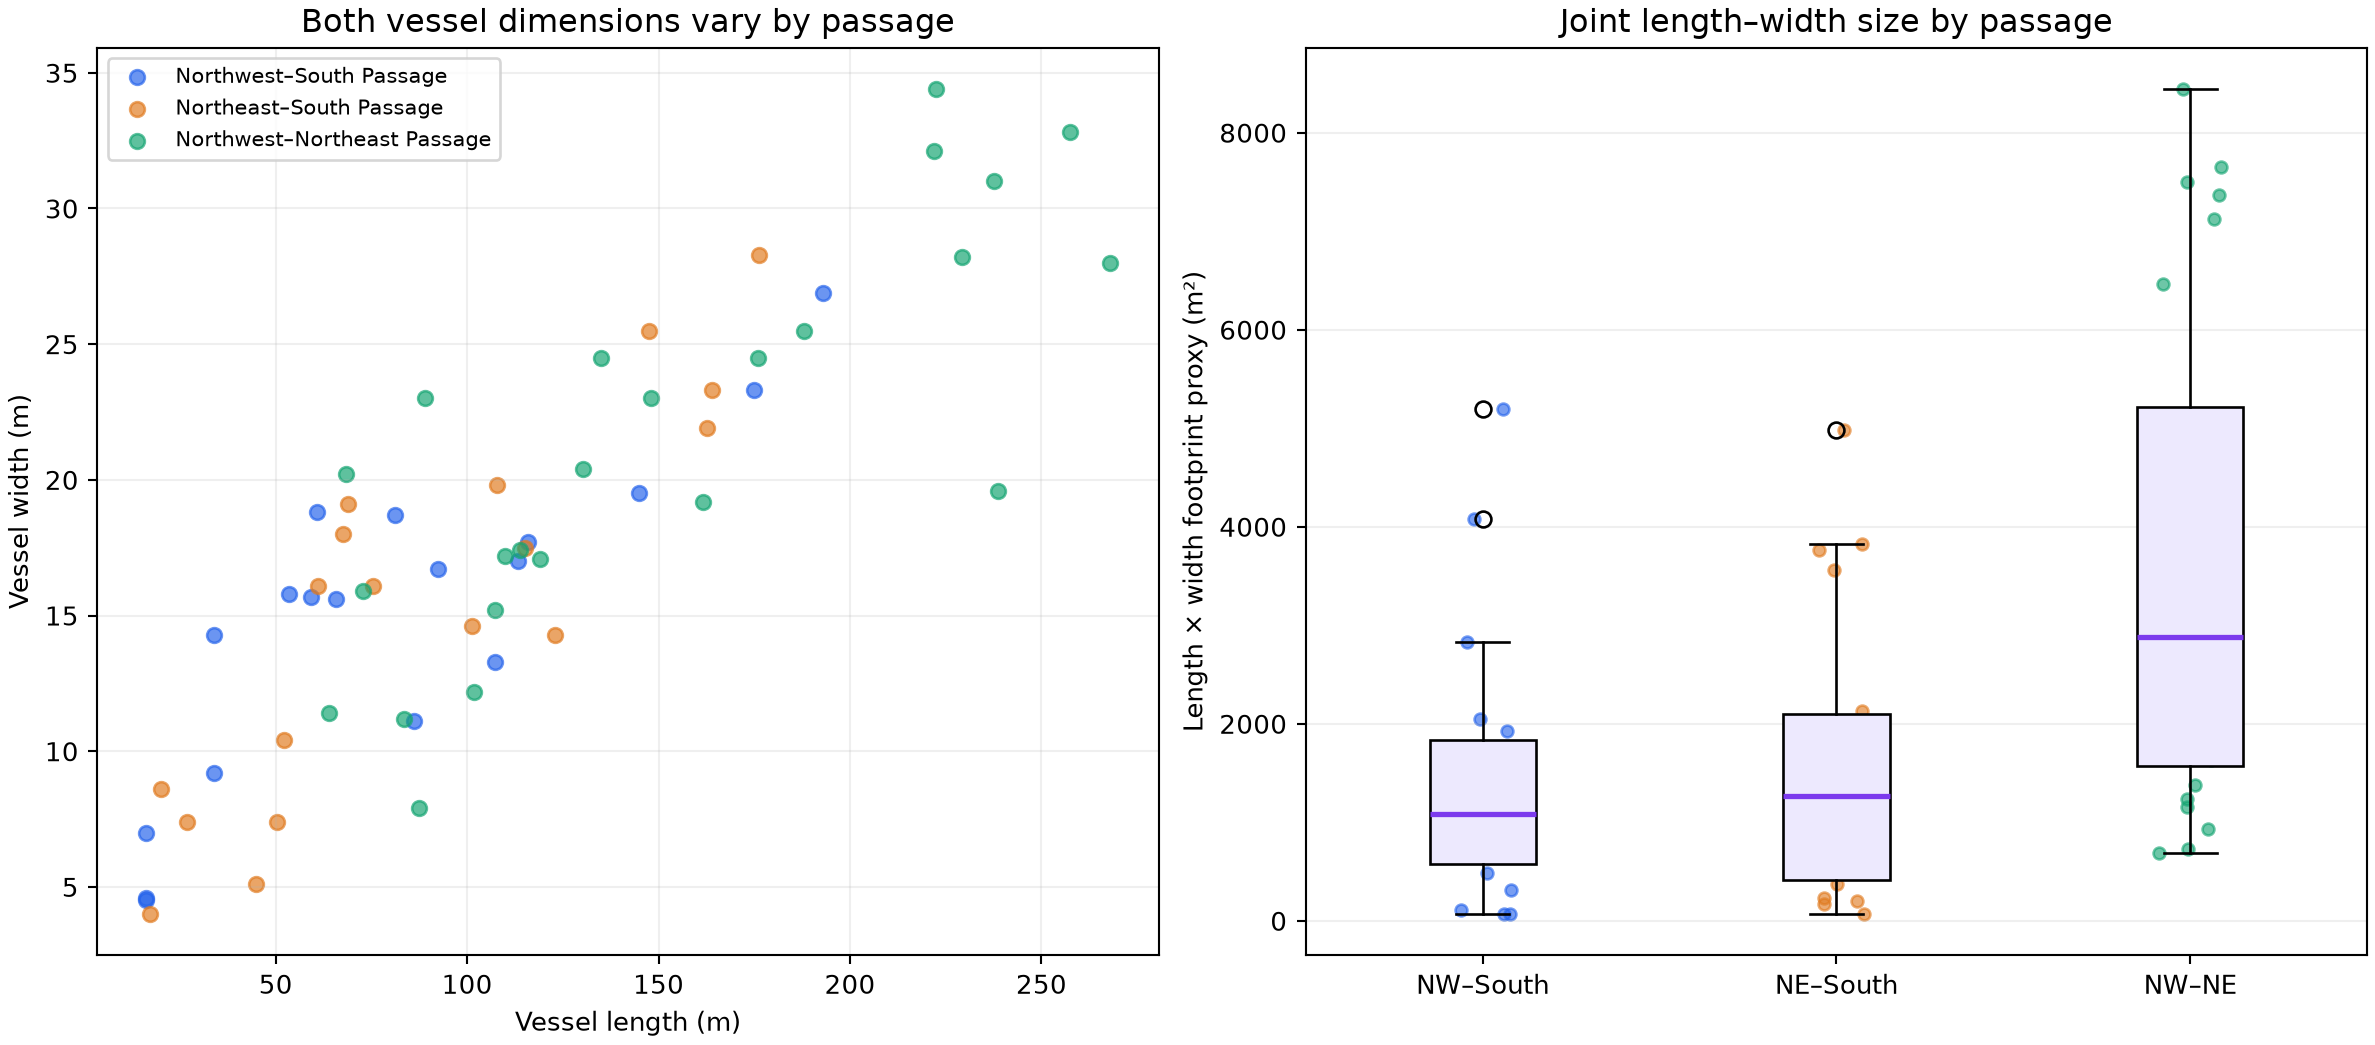

In [ ]:
import pandas as pd
ships=pd.read_csv(user_dataset_path)
ships['footprint_proxy_m2']=ships.length_m*ships.width_m
print(ships[['length_m','width_m','footprint_proxy_m2']].describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/vessel_length_by_passage.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "vessel_dimensions_route_relationship",
  "insight": "Larger vessels are more likely to travel on the northwest–northeast route, while smaller vessels are more likely to travel on the other two routes.",
  "insight_value": {
    "median_dimensions": {
      "NW_S": {
        "length_m": 73.4,
        "width_m": 15.8
      },
      "NE_S": {
        "length_m": 72.2,
        "width_m": 16.1
      },
      "NW_NE": {
        "length_m": 132.6,
        "width_m": 20.3
      }
    },
    "median_length_width_footprint_proxy_m2": {
      "NW_S": 1084.0,
      "NE_S": 1267.3,
      "NW_NE": 2880.4
    },
    "share_length_at_least_120m_and_width_at_least_18m": {
      "NW_S": 0.17,
      "NE_S": 0.22,
      "NW_NE": 0.54
    }
  },
  "plot": {
    "plot_type": "dimension_scatter_and_joint_size_boxplot",
    "title": "Vessel Length and Width by Island Passage",
    "file": "visualizations/vessel_length_by_passage.png",
    "description": "Length–width scatter and their footprint proxy show overlapping, probabilistic size differences without assigning small/large labels."
  },
  "question": "How are vessel length and width jointly associated with passage choice around the island?",
  "actionable_insight": "Link both continuous vessel dimensions to inferred passage assignment and compare their joint footprint proxy.",
  "code": "import pandas as pd\nships=pd.read_csv(user_dataset_path)\nships['footprint_proxy_m2']=ships.length_m*ships.width_m\nprint(ships[['length_m','width_m','footprint_proxy_m2']].describe())",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference",
    "vessel_length",
    "vessel_width",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 13)

Vessel traffic around the island is organized into three main passage routes. Two of the three main routes show a stable speed distribution and a consistent direction of travel, while the other shows a smooth change of direction. Larger vessels are more likely to travel on the northwest–northeast route, while smaller vessels are more likely to travel on the other two routes.